In [1]:
import sys
sys.path.append('../')
from hypgs.models.hsn_pyg import HSN
from hypgs.utils.plot import plot_wavelets, get_hyperedge_pos_df, compute_enlarged_hulls, plot_hulls
from hypgs.utils.graph_build import calcualte_voronoi_from_coords, build_graph_from_cell_coords, build_graph_from_voronoi_polygons, build_voronoi_polygon_to_cell_mapping, plot_voronoi_polygons, plot_graph, assign_attributes
from hypgs.models.hsn_pyg import HyperScatteringModule
from hypgs.utils.data import get_hyperedge_index
import scanpy as sc
import numpy as np
import pandas as pd
import torch
from torch_geometric.utils.convert import from_networkx
from hypgs.utils.data import HGDataset
from dhg import Hypergraph
import scprep
import matplotlib.pyplot as plt
import re
import phate
from phate.cluster import kmeans

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/torch_geometric/typing.py:47: UserWarning: An issue occurred while importing 'pyg-lib'. Disabling its usage. Stacktrace: /gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/libpyg.so: undefined symbol: _ZN2at4_ops12split_Tensor4callERKNS_6TensorEN3c106SymIntEl
  warnings.warn(f"An issue occurred while importing 'pyg-lib'. "
/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/torch_geometric/typing.py:90: UserWarning: An issue occurred while importing 'torch-spline-conv'. Disabling its usage. Stacktrace: /gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.con

In [2]:
# adata = sc.read_h5ad("../data/A23-290-CP_preprocessed.h5ad")
# sc.pp.highly_variable_genes(adata, inplace=True)
# adata.write_h5ad("../data/A23-290-CP_preprocessed_hvg.h5ad")

In [3]:
adata = sc.read_h5ad("../data/A23-290-CP_preprocessed_hvg.h5ad")

In [4]:
# np.random.seed(0)
# subset_idx = np.random.choice(adata.shape[0], 10000, replace=False)
# adata_subset = adata[subset_idx, :]

In [5]:
adata_subset = adata

In [6]:
adata_subset.obsm

AxisArrays with keys: X_phate, X_spatial, spatial

In [7]:
coordinates = adata_subset.obsm['X_spatial']
coordinates = coordinates - coordinates.min(axis=0)
xmax, ymax = coordinates.max(axis=0)
voronoi_polygons = calcualte_voronoi_from_coords(coordinates[:, 0], coordinates[:, 1])
cell_data = pd.DataFrame(np.c_[adata_subset.obs.index, coordinates], columns=['CELL_ID', 'X', 'Y'])
G, node_to_cell_mapping = build_graph_from_cell_coords(cell_data, voronoi_polygons)
G = assign_attributes(G, cell_data, node_to_cell_mapping)

In [8]:
G

In [9]:
X_cmbn = adata_subset[:, adata_subset.var['highly_variable']].X.toarray()
data = from_networkx(G)
data.x = torch.tensor(X_cmbn)
original_dataset = [data]
to_hg_func = lambda g: Hypergraph.from_graph_kHop(g, 1)
dataset = HGDataset(original_dataset, to_hg_func)

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/torch_geometric/utils/convert.py:260: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /opt/conda/conda-bld/pytorch_1670525539683/work/torch/csrc/utils/tensor_new.cpp:230.)
  data[key] = torch.tensor(value)
Converting to hypergraph data: 100%|██████████| 1/1 [00:27<00:00, 27.70s/it]


In [10]:
matches = [bool(re.search('myl|myh|cald|mgp', name.lower())) for name in adata_subset.var.index]
matches = matches & adata_subset.var['highly_variable']
markers = adata_subset.var[matches].index.tolist()
markers = [m for m in markers if m not in ['MYH10', 'MYLK']]

In [11]:
len(markers)

5

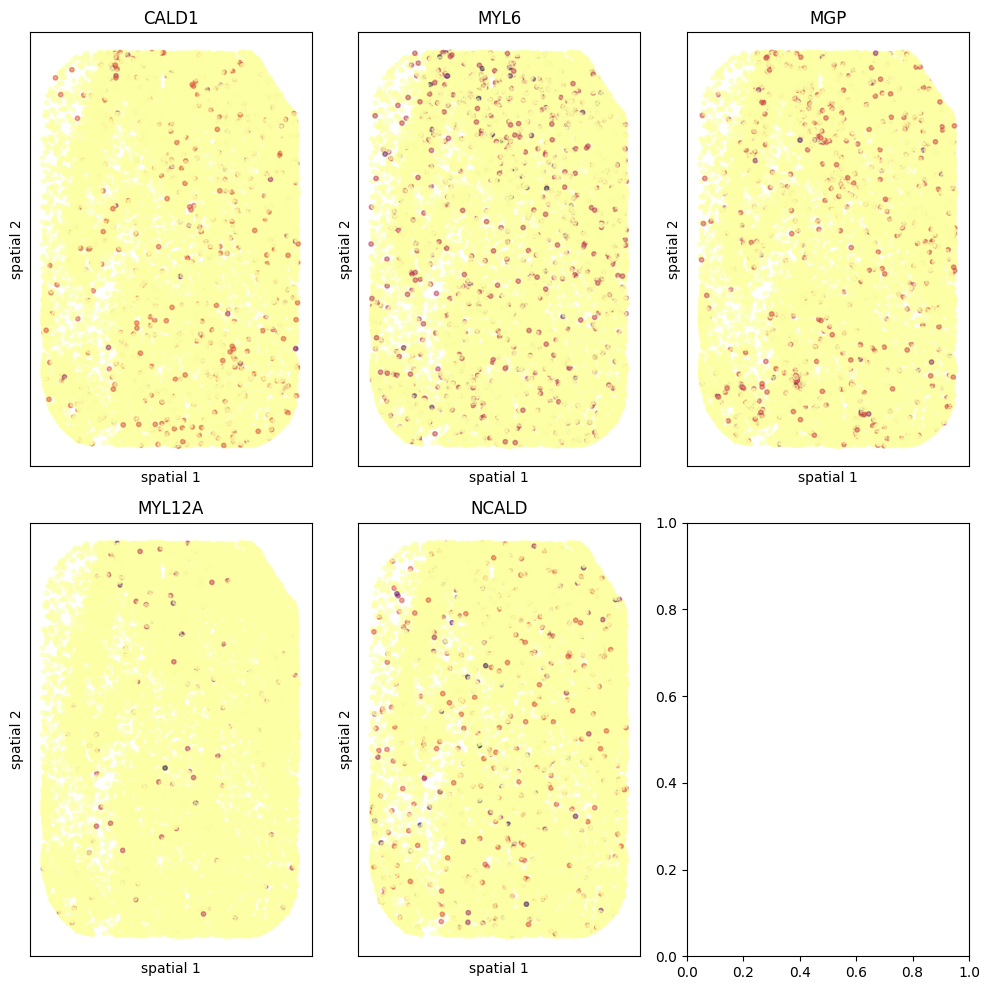

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(10, 10))

for i, marker in enumerate(markers):
    node_feat = adata_subset[:, marker].X.toarray()
    ax = axes[i // 3, i % 3]
    scprep.plot.scatter2d(adata_subset.obsm['X_spatial'], c=-node_feat, s=10, alpha=0.5, ax=ax, colorbar=False)
    ax.set_xlabel('spatial 1')
    ax.set_ylabel('spatial 2')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'{marker}')

plt.tight_layout()
plt.show()


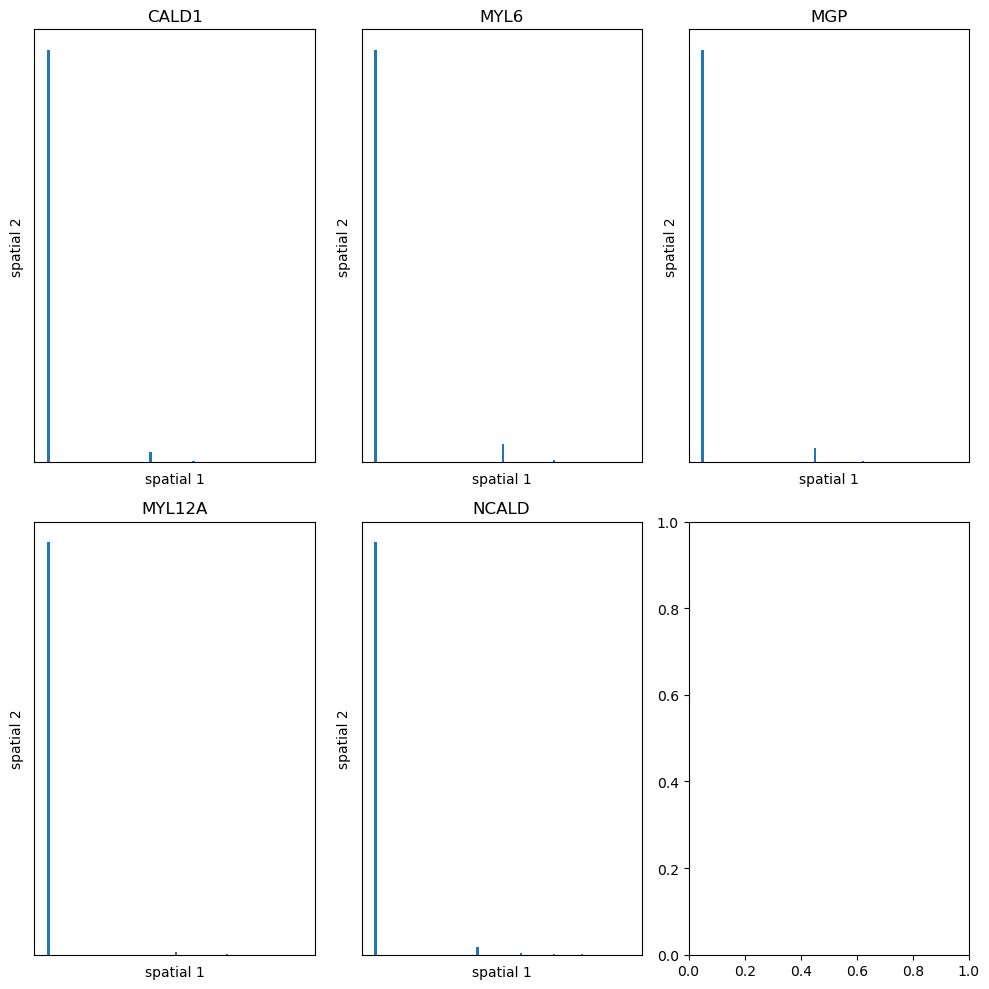

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(10, 10))

for i, marker in enumerate(markers):
    node_feat = adata_subset[:, marker].X.toarray()
    ax = axes[i // 3, i % 3]
    ax.hist(node_feat, bins=100)
    ax.set_xlabel('spatial 1')
    ax.set_ylabel('spatial 2')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'{marker}')

plt.tight_layout()
plt.show()


In [15]:
adata_subset.shape

(21326, 6695)

In [16]:
import magic
magic_op = magic.MAGIC()
adata_magic = magic_op.fit_transform(adata_subset, genes=markers)

Calculating MAGIC...
  Running MAGIC on 21326 cells and 6695 genes.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.57 seconds.
    Calculating KNN search...
    Calculated KNN search in 126.69 seconds.
    Calculating affinities...
    Calculated affinities in 125.67 seconds.
  Calculated graph and diffusion operator in 252.99 seconds.
  Calculating imputation...
  Calculated imputation in 0.02 seconds.
Calculated MAGIC in 253.06 seconds.


In [18]:
adata_magic.write_h5ad("../data/A23-290-CP_preprocessed_hvg_magic.h5ad")

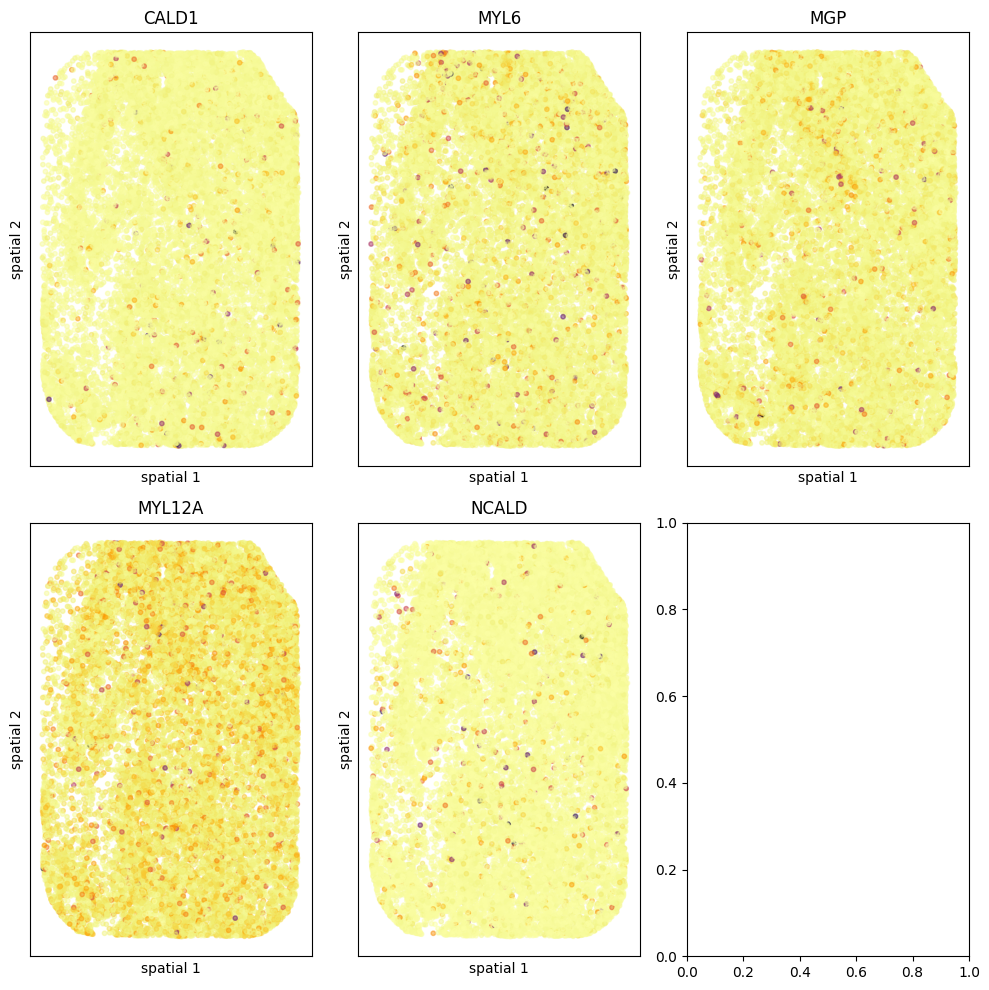

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(10, 10))

for i, marker in enumerate(markers):
    node_feat = adata_magic[:, marker].X.toarray()
    ax = axes[i // 3, i % 3]
    scprep.plot.scatter2d(adata_subset.obsm['X_spatial'], c=-node_feat, s=10, alpha=0.5, ax=ax, colorbar=False)
    ax.set_xlabel('spatial 1')
    ax.set_ylabel('spatial 2')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'{marker}')

plt.tight_layout()
plt.show()


In [7]:
# make contrastive labels
node_feat = adata_subset[:, markers].X.toarray()
print(node_feat.min(axis=0), node_feat.max(axis=0))
node_feat_binarized = node_feat > 0

[0. 0. 0. 0. 0.] [2.4494898 2.        2.236068  2.        2.4494898]


In [8]:
np.save('../data/A23_label.npy', node_feat_binarized)

In [9]:
dists = []
for arr in node_feat_binarized.T:
    dists.append(np.logical_xor(arr[:, None], arr))
dists = np.array(dists)

In [10]:
np.save('../data/A23_XOR_dists.npy', dists)

In [13]:
a = dists[:,:100,:100]
a1 = a[0]

In [19]:
a.shape

(5, 100, 100)

In [42]:
a1triu = a1[np.triu_indices(a1.shape[1], k=1)]

In [43]:
triu_ind = np.triu_indices(a.shape[1], k=1)
atriu = a[:, triu_ind[0], triu_ind[1]]

In [33]:
(a[:, triu_ind[0], triu_ind[1]]*1. - a1[np.triu_indices(a1.shape[1], k=1)]*1.).shape

(5, 4950)

In [44]:
atriu = torch.tensor(atriu, dtype=torch.float32)
a1triu = torch.tensor(a1triu, dtype=torch.float32).unsqueeze(0).expand(atriu.shape[0], -1)
torch.nn.functional.mse_loss(atriu, a1triu)

tensor(0.1617)

In [50]:
(a1triu * w.unsqueeze(1)).size()

torch.Size([5, 4950])

In [51]:
a1triu.size()

torch.Size([5, 4950])

In [52]:
w = torch.tensor(np.random.rand(1))
w.unsqueeze(1)

tensor([[0.5994]], dtype=torch.float64)

In [13]:
model = HyperScatteringModule(in_channels=X_cmbn.shape[1], 
              trainable_laziness = False,
              trainable_scales = False, 
              activation = None, # just get one layer of wavelet transform 
              fixed_weights=True, 
              normalize='right', 
              reshape=False,
        )

In [14]:
s_nodes, s_edges = model(dataset[0].x.float(), dataset[0].edge_index, hyperedge_attr = dataset[0].edge_attr)

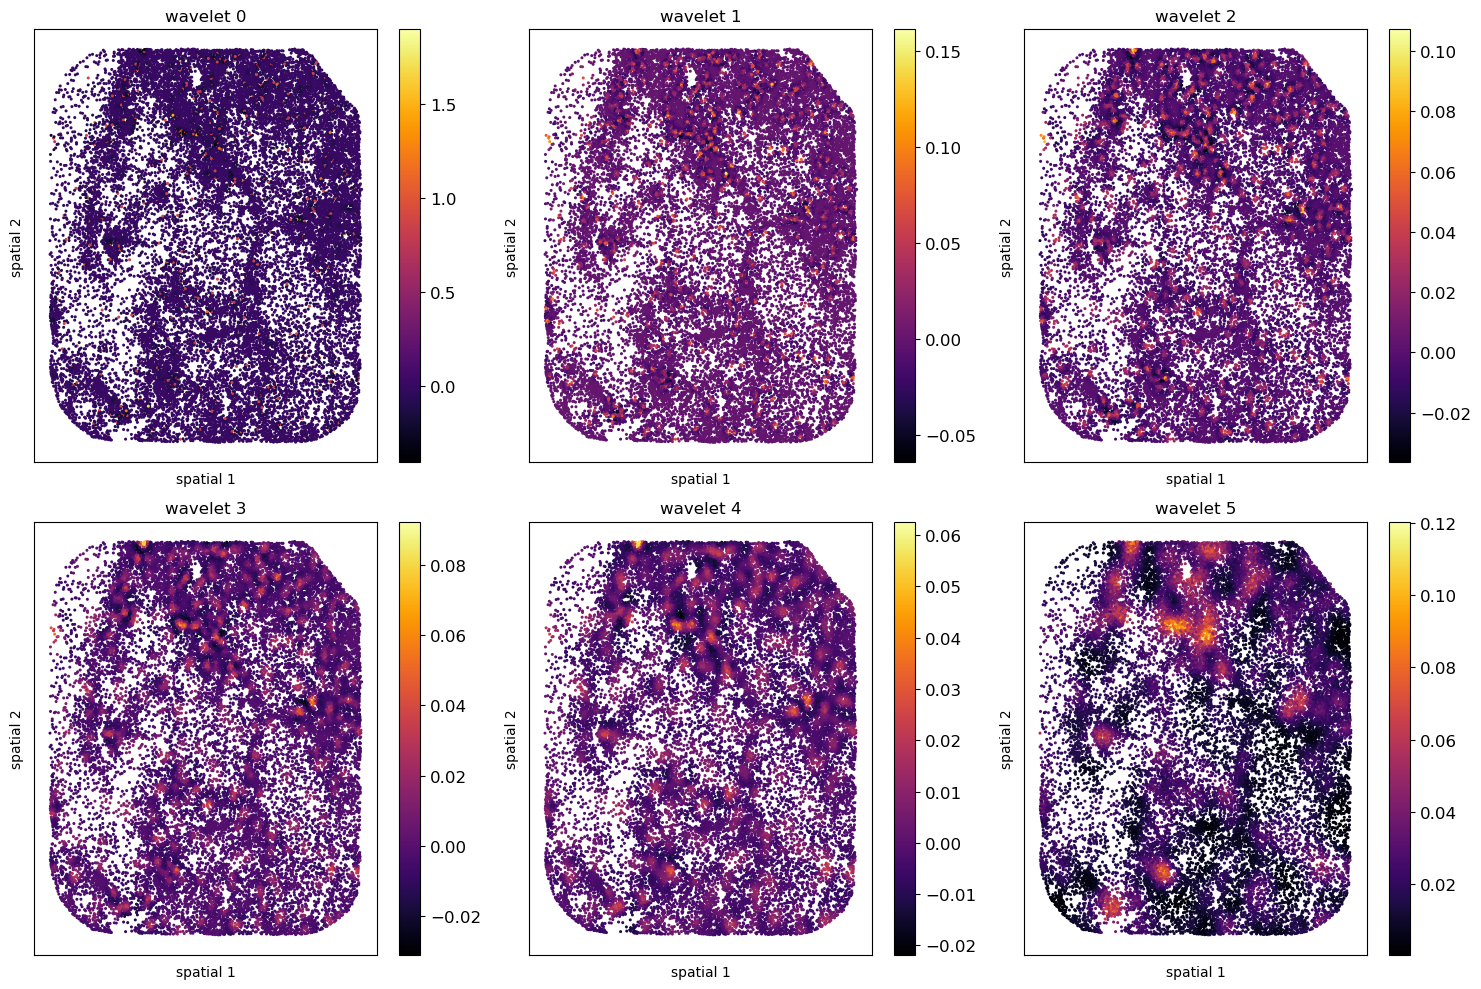

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, ax in enumerate(axes.flatten()):
    node_feat = s_nodes[0,i,:,0].detach().cpu().numpy()
    scprep.plot.scatter2d(adata_subset.obsm['X_spatial'], c=node_feat, ax=ax)
    ax.set_xlabel('spatial 1')
    ax.set_ylabel('spatial 2')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'wavelet {i}')

plt.tight_layout()
plt.show()


In [16]:
wvs = [s_edges[0,i,...].detach().cpu().numpy() for i in range(6)]
# wv_all = s_edges.view(8475, -1).detach().cpu().numpy()
wv_all = np.concatenate(wvs, axis=1)
phate_op = phate.PHATE(n_components=2)
wv_phate = phate_op.fit_transform(wv_all)

Calculating PHATE...
  Running PHATE on 21326 observations and 582 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 1.02 seconds.
    Calculating KNN search...
    Calculated KNN search in 48.47 seconds.
    Calculating affinities...
    Calculated affinities in 2.90 seconds.
  Calculated graph and diffusion operator in 52.47 seconds.
  Calculating landmark operator...
    Calculating SVD...
    Calculated SVD in 1.68 seconds.
    Calculating KMeans...
    Calculated KMeans in 7.36 seconds.
  Calculated landmark operator in 10.64 seconds.
  Calculating optimal t...
    Automatically selected t = 26
  Calculated optimal t in 3.57 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 2.18 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 5.93 seconds.
Calculated PHATE in 74.79 seconds.


<AxesSubplot:xlabel='PHATE1', ylabel='PHATE2'>

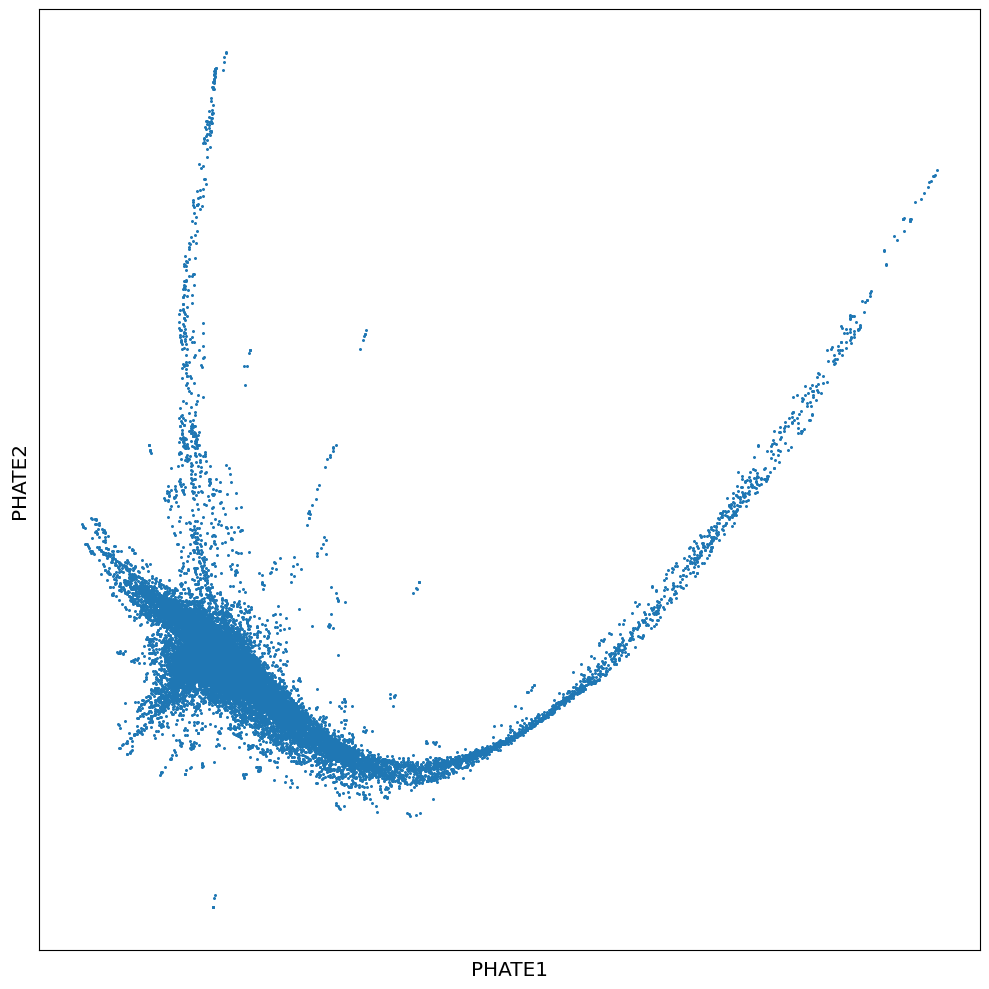

In [17]:
scprep.plot.scatter2d(wv_phate, figsize=(10, 10), ticks=False, label_prefix='PHATE')

In [18]:
phate_cluster_labels = kmeans(phate_op, n_clusters=3)

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


<AxesSubplot:xlabel='PHATE1', ylabel='PHATE2'>

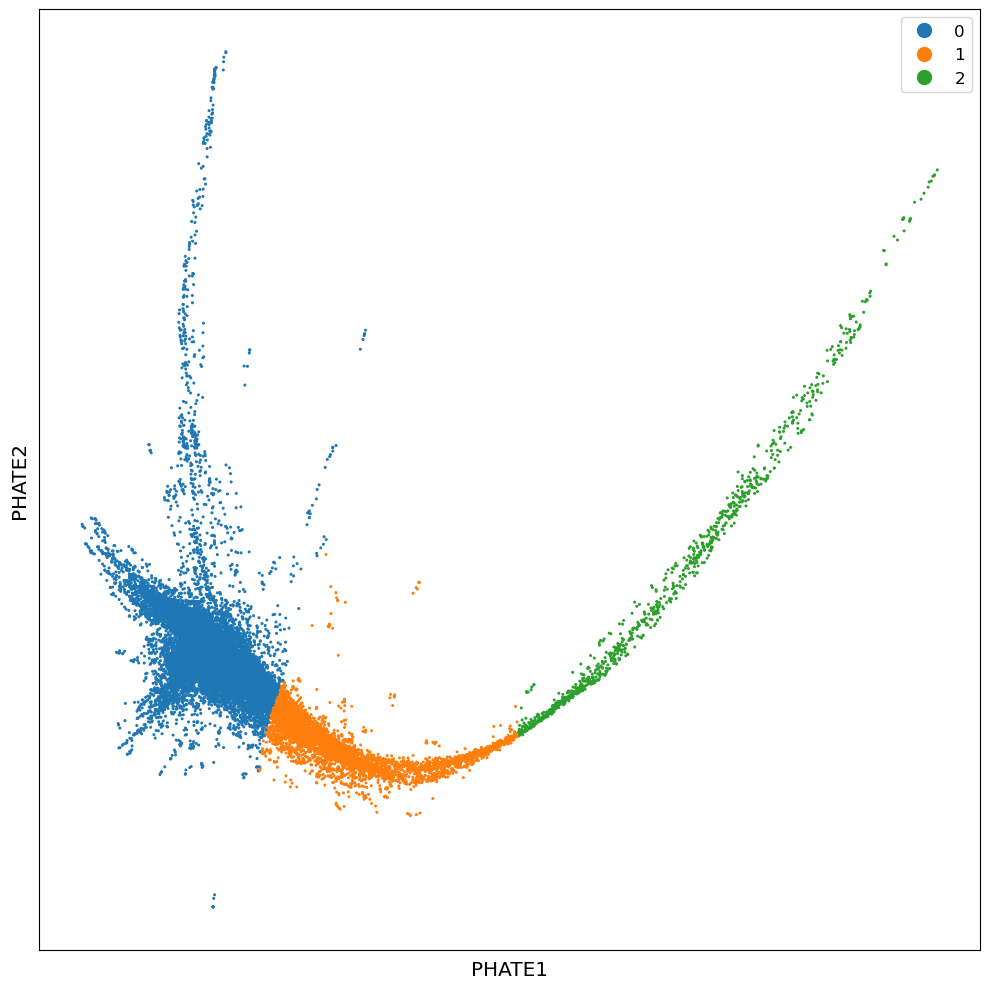

In [19]:
scprep.plot.scatter2d(wv_phate, figsize=(10, 10), ticks=False, c=phate_cluster_labels, label_prefix='PHATE')

In [20]:
eidf = get_hyperedge_pos_df(dataset[0], coordinates)
enlarged_hulls = compute_enlarged_hulls(eidf)

In [21]:
node_feats = s_nodes[0,:,:,0].detach().cpu().numpy().T
edge_feats = s_edges[0,:,:,0].detach().cpu().numpy().T
plot_wavelets(node_feats, edge_feats, coordinates, enlarged_hulls)

KeyboardInterrupt: 

In [22]:
# save results
torch.save(s_nodes, '../data/A23_s_nodes.pt')
torch.save(s_edges, '../data/A23_s_edges.pt')

In [23]:
pca_loadings = phate_op.graph.data_nu
pca_components = phate_op.graph.data_pca.components_

In [24]:
phate_operator = phate.PHATE()
Y_phate = phate_operator.fit_transform(pca_loadings)

Calculating PHATE...
  Running PHATE on 21326 observations and 100 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculated KNN search in 55.26 seconds.
    Calculating affinities...
    Calculated affinities in 1.92 seconds.
  Calculated graph and diffusion operator in 57.24 seconds.
  Calculating landmark operator...
    Calculating SVD...
    Calculated SVD in 1.91 seconds.
    Calculating KMeans...
    Calculated KMeans in 11.46 seconds.
  Calculated landmark operator in 14.91 seconds.
  Calculating optimal t...
    Automatically selected t = 28
  Calculated optimal t in 3.47 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 2.20 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 4.59 seconds.
Calculated PHATE in 82.43 seconds.


<AxesSubplot:xlabel='PHATE 1', ylabel='PHATE 2'>

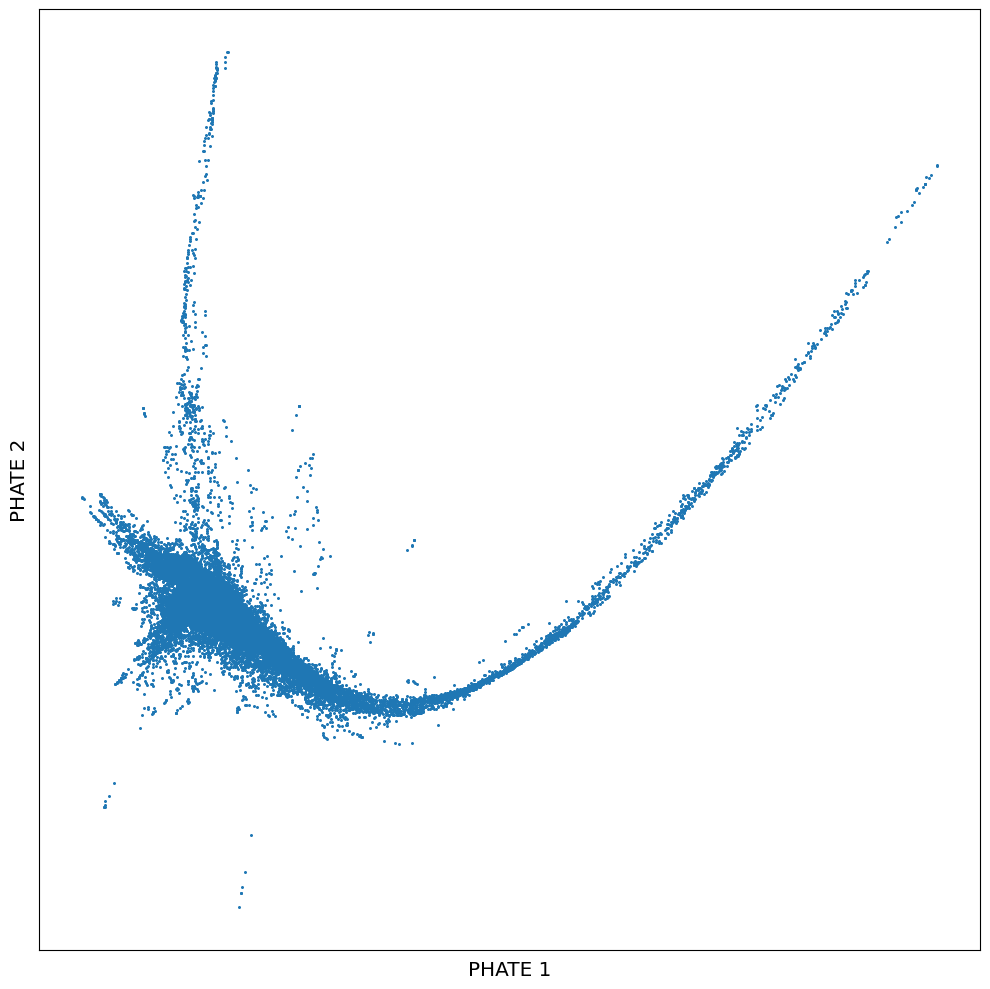

In [25]:
scprep.plot.scatter2d(Y_phate, figsize=(10, 10), ticks=False, label_prefix='PHATE ')

In [27]:
torch.save(dataset[0], '../data/A23_dataset.pt')

In [28]:
np.save('../data/A23_pca_loadings.npy', pca_loadings)

In [29]:
np.save('../data/A23_pca_components.npy', pca_components)

In [30]:
np.save('../data/A23_phate.npy', Y_phate)

In [32]:
dataset[0].edge_index

tensor([[    0,   237,  6033,  ..., 16393, 20219, 21325],
        [    0,     0,     0,  ..., 21325, 21325, 21325]])

In [135]:
from torch_geometric.nn.conv import MessagePassing
from torch_geometric.utils import scatter, softmax
from typing import Tuple, Optional


class HyperEdgeFeatureMomentsAggregator(MessagePassing):
    """
    Aggregates node features of a hyperedge by computing the moments of the node features.
    k: number of moments to compute
    mean_center: whether to mean center the node features before computing the moments
    """
    def __init__(
            self,
            k, 
            mean_center,
            **kwargs,
    ):
        kwargs.setdefault('aggr', 'mean')
        super().__init__(flow='source_to_target', node_dim=0, **kwargs)
        self.k = k
        self.mean_center = mean_center
    
    def forward(self, x: torch.Tensor, hyperedge_index: torch.Tensor,
                num_edges: Optional[int] = None) -> torch.Tensor:
        
        num_nodes = x.size(0)

        if num_edges is None:
            num_edges = 0
            if hyperedge_index.numel() > 0:
                num_edges = int(hyperedge_index[1].max()) + 1

        x_moments = torch.stack([x ** i for i in range(1, self.k + 1)]).permute(1,0,2)
        sh1, sh2, sh3 = x_moments.size()
        xm_flatten = x_moments.reshape(sh1, sh2 * sh3)
        out_edge = self.propagate(hyperedge_index, x=xm_flatten,
                            size=(num_nodes, num_edges))
        out_edge = out_edge.reshape(num_edges, sh2, sh3)

        # if self.mean_center:
        #     x_mean = scatter(x, hyperedge_index, dim=0, dim_size=num_edges, reduce='mean')
        #     out_edge = out_edge - x_mean.unsqueeze(1)

        return out_edge # shape (num_edges, k, num_features)


    def message(self, x_j: torch.Tensor) -> torch.Tensor:
        return x_j

In [108]:
# from torch_geometric.utils import scatter

# def aggregate_moments_hyperedge(x: torch.Tensor, hyperedge_index: torch.Tensor, k: int, mean_center: bool, num_edges: int = None) -> torch.Tensor:
#     if num_edges is None:
#         num_edges = 0
#         if hyperedge_index.numel() > 0:
#             num_edges = int(hyperedge_index[1].max()) + 1
    
#     x_mean = scatter(x, hyperedge_index[1], dim=0, dim_size=num_edges, reduce='mean')
#     return x_mean

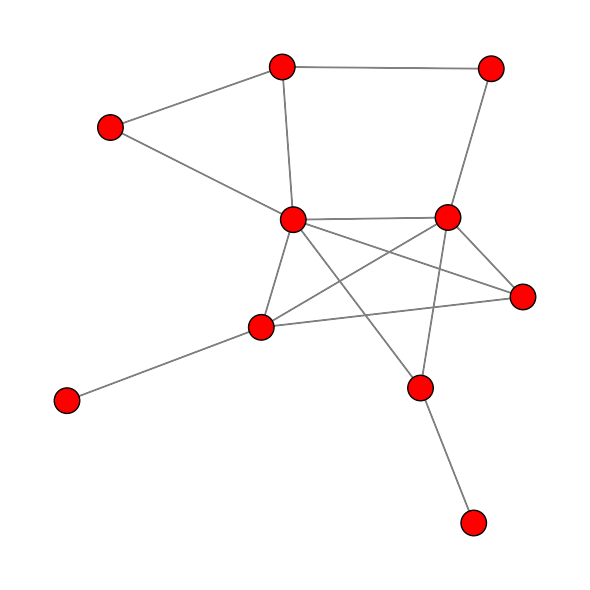

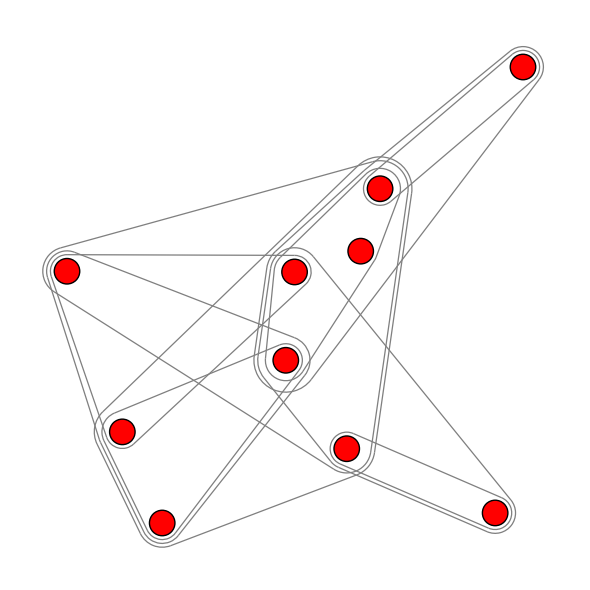

In [98]:
from dhg import Graph

import networkx as nx
import matplotlib.pyplot as plt

# Create a random graph
g = nx.gnm_random_graph(10, 15)

G = Graph(g.number_of_nodes(), [e for e in g.edges])
HG = Hypergraph.from_graph_kHop(G, 1)
G.draw()
HG.draw()

In [101]:
edge_index = get_hyperedge_index(HG)

In [102]:
edge_index

tensor([[0, 4, 7, 9, 1, 5, 7, 2, 8, 3, 4, 0, 3, 4, 7, 9, 1, 5, 6, 9, 5, 6, 9, 0,
         1, 4, 7, 8, 9, 2, 7, 8, 9, 0, 4, 5, 6, 7, 8, 9],
        [0, 0, 0, 0, 1, 1, 1, 2, 2, 3, 3, 4, 4, 4, 4, 4, 5, 5, 5, 5, 6, 6, 6, 7,
         7, 7, 7, 7, 7, 8, 8, 8, 8, 9, 9, 9, 9, 9, 9, 9]])

In [103]:
x = torch.randn(10, 3)

In [104]:
x

tensor([[-0.9149, -1.4694, -0.8106],
        [ 0.6679, -0.5170,  0.7154],
        [-0.6418, -0.1419,  0.5477],
        [-0.3153, -0.4938, -0.2879],
        [-1.4580,  1.3721, -0.9891],
        [-1.1465,  0.1557,  0.2946],
        [-1.5081, -2.0925, -0.0643],
        [ 1.6238, -0.9658,  1.8329],
        [ 1.2201, -1.3555,  0.3434],
        [-0.8146, -0.7619, -0.6746]])

In [136]:
agger = HyperEdgeFeatureMomentsAggregator(k=1, mean_center=True)

In [137]:
means = agger(x, edge_index)

In [138]:
means = means.squeeze()

In [139]:
means

tensor([[-0.3909, -0.4562, -0.1604],
        [ 0.3817, -0.4424,  0.9476],
        [ 0.2892, -0.7487,  0.4456],
        [-0.8867,  0.4392, -0.6385],
        [-0.3758, -0.4637, -0.1859],
        [-0.7003, -0.8039,  0.0677],
        [-1.1564, -0.8996, -0.1481],
        [ 0.0541, -0.6162,  0.0696],
        [ 0.3469, -0.8063,  0.5123],
        [-0.4283, -0.7310, -0.0097]])

In [129]:
edge_index

tensor([[0, 4, 7, 9, 1, 5, 7, 2, 8, 3, 4, 0, 3, 4, 7, 9, 1, 5, 6, 9, 5, 6, 9, 0,
         1, 4, 7, 8, 9, 2, 7, 8, 9, 0, 4, 5, 6, 7, 8, 9],
        [0, 0, 0, 0, 1, 1, 1, 2, 2, 3, 3, 4, 4, 4, 4, 4, 5, 5, 5, 5, 6, 6, 6, 7,
         7, 7, 7, 7, 7, 8, 8, 8, 8, 9, 9, 9, 9, 9, 9, 9]])

In [132]:
def mean_manual(x, edge_index):
    means = torch.zeros_like(x)
    for i in range(edge_index[1].max()+1):
        ids = edge_index[0][edge_index[1] == i]
        means[i,:] = x[ids,:].mean(dim=0)
    return means

In [133]:
means2 = mean_manual(x, edge_index)

In [134]:
means2

tensor([[-0.3909, -0.4562, -0.1604],
        [ 0.3817, -0.4424,  0.9476],
        [ 0.2892, -0.7487,  0.4456],
        [-0.8867,  0.4392, -0.6385],
        [-0.3758, -0.4637, -0.1859],
        [-0.7003, -0.8039,  0.0677],
        [-1.1564, -0.8996, -0.1481],
        [ 0.0541, -0.6162,  0.0696],
        [ 0.3469, -0.8063,  0.5123],
        [ 0.0000,  0.0000,  0.0000]])